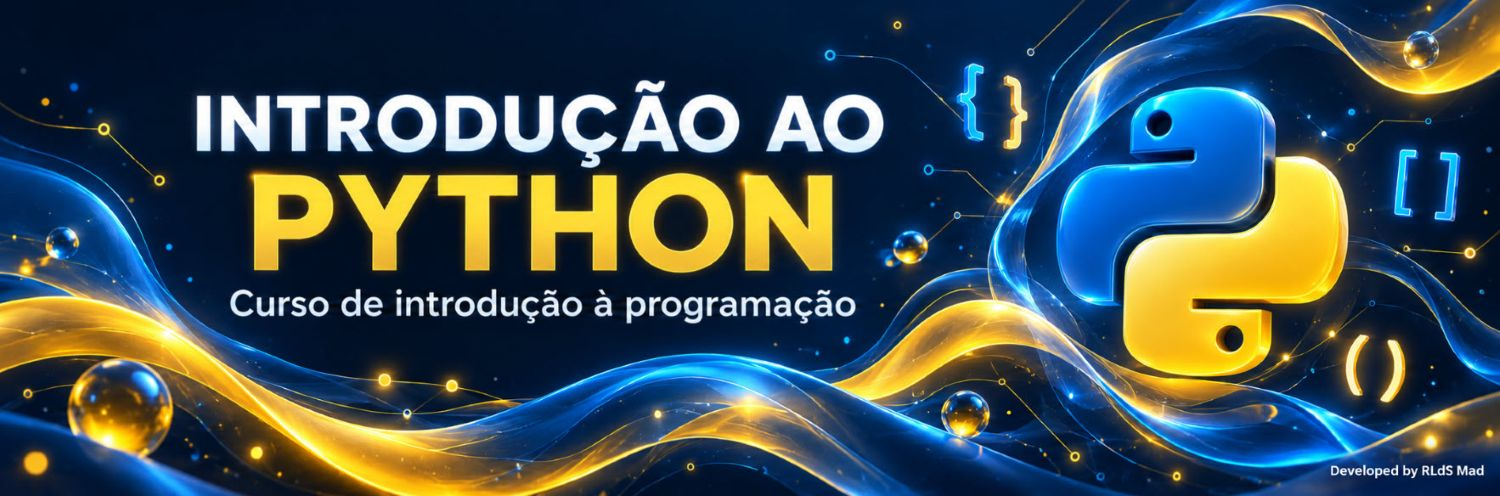

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python_v2/nivel_1_introducao/RLdS_23_Pandas_Basico.ipynb)


# Capítulo 23 – Pandas básico
## Primeiros passos com tabelas em Python

Este notebook é a tua **introdução ao Pandas**. Neste módulo, cada operação é apresentada isoladamente e acompanhada de uma explicação do resultado.

**Pré-requisitos:** variáveis, listas, dicionários e funções de Python (capítulos 4 a 18). Ajuda ter feito o capítulo 22 (NumPy), mas não é obrigatório; não precisas de experiência com Pandas.

**Duração sugerida:** 4–6 horas, incluindo exercícios.

Ao terminar, deverás conseguir criar e explorar tabelas, selecionar e filtrar dados, alterar colunas, calcular resumos e ler e guardar um CSV simples.

### Como utilizar
1. Abre o notebook no Jupyter, no VS Code ou no Colab.
2. Seleciona um kernel Python. Executa cada célula com **Shift + Enter**, de cima para baixo.
3. Lê a interpretação depois de cada exemplo. Altera valores para perceber o efeito.
4. Resolve os exercícios antes de consultar as soluções.
5. Para confirmar a reprodução, reinicia o kernel e executa todas as células.

Os dados são fictícios e são criados neste notebook. Depois de instaladas as dependências, não é necessária ligação à Internet (o Colab já as inclui). As saídas guardadas são uma execução de referência.

### Percurso
1. O que é Pandas e como importar
2. Listas, arrays, Series e DataFrames
3. Criar e explorar tabelas
4. Índices e seleção com `[]`, `loc` e `iloc`
5. Filtrar com uma ou várias condições
6. Criar, alterar, renomear e remover dados
7. Tipos, cálculos, texto e ordenação
8. Resumos, valores ausentes e duplicados
9. Primeira leitura e escrita de CSV
10. Desafio de consolidação e soluções

## 1. O que é Pandas?

**Pandas** é uma biblioteca de Python para trabalhar com dados organizados em tabelas. É útil para ler ficheiros, selecionar informação, fazer cálculos e resumir dados.


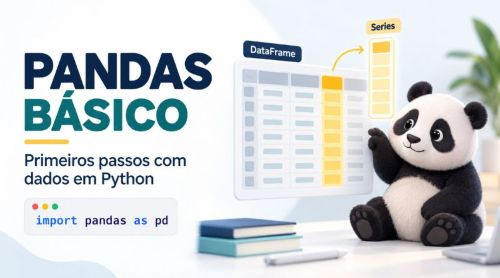


Imagina uma folha de cálculo: as **linhas** representam observações e as **colunas** representam características. No nosso exemplo principal, cada linha é um produto de uma papelaria e cada coluna descreve uma característica desse produto.

Pandas não substitui o Python: acrescenta estruturas e operações próprias para dados tabulares.

### Instalar, se necessário
A instalação é feita uma vez por ambiente; a importação é feita em cada nova sessão. `%pip` instala no ambiente Colab, no kernel Jupyter ou VS Code.

In [1]:
# O Colab já inclui estas bibliotecas. Noutros ambientes, descomenta a linha seguinte se faltar alguma.
# %pip install pandas numpy

## 1.1 Importar as bibliotecas

`import pandas as pd` importa Pandas e dá-lhe o nome curto `pd`. É uma convenção, não uma palavra reservada. NumPy só será usado numa comparação inicial.

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("Versão de Pandas:", pd.__version__)

Versão de Pandas: 3.0.6


**Como interpretar:** `pd` permite aceder a objetos como `pd.Series` e `pd.DataFrame`. Se aparecer `NameError: pd is not defined`, executa esta célula primeiro.

## 2. Lista, array, Series e DataFrame

Começamos pelos mesmos três preços em estruturas diferentes. A lista pertence ao Python; o array pertence ao NumPy; a Series pertence ao Pandas.

In [3]:
lista_precos = [2.5, 1.2, 8.0]
array_precos = np.array(lista_precos)
serie_precos = pd.Series(lista_precos, name="preco")

print("Lista:", lista_precos)
print("Array:", array_precos)
display(serie_precos)
print(type(lista_precos), type(array_precos), type(serie_precos))

Lista: [2.5, 1.2, 8.0]
Array: [2.5 1.2 8. ]


0    2.5
1    1.2
2    8.0
Name: preco, dtype: float64

<class 'list'> <class 'numpy.ndarray'> <class 'pandas.Series'>


**Como interpretar:** A Series mostra etiquetas de índice à esquerda e valores à direita. Por defeito, o índice começa em zero. `name` dá um nome à Series; não altera os valores.

| Estrutura | Biblioteca | Organização típica | Exemplo de utilização |
|---|---|---|---|
| `list` | Python | Sequência de elementos | Guardar objetos variados |
| `ndarray` | NumPy | Array de uma ou mais dimensões | Cálculo numérico |
| `Series` | Pandas | Uma dimensão com índice | Uma coluna de dados |
| `DataFrame` | Pandas | Tabela de linhas e colunas | Várias características por observação |

Uma Series tem um tipo de dados (`dtype`). Um DataFrame pode ter tipos diferentes de coluna para coluna. Um array NumPy comum tem um tipo único para os seus elementos.

## 2.1 Uma Series com etiquetas

As etiquetas podem ser nomes em vez de números. Usa `.loc` para selecionar por etiqueta.

In [4]:
precos = pd.Series([2.5, 1.2, 8.0], index=["Caderno", "Caneta", "Agenda"], name="preco")
display(precos)
print("Preço da Caneta:", precos.loc["Caneta"])
print("Segundo preço:", precos.iloc[1])
display(precos * 2)

Caderno    2.5
Caneta     1.2
Agenda     8.0
Name: preco, dtype: float64

Preço da Caneta: 1.2
Segundo preço: 1.2


Caderno     5.0
Caneta      2.4
Agenda     16.0
Name: preco, dtype: float64

**Como interpretar:** `loc["Caneta"]` procura uma etiqueta. `iloc[1]` procura a segunda posição. Multiplicar a Series por 2 multiplica cada valor; não duplica a sequência como aconteceria com uma lista Python.

### Prática - exercício 1

Cria uma Series chamada `temperaturas`, com os valores 18, 21 e 16 e as etiquetas Lisboa, Faro e Porto. Mostra a temperatura do Porto com `loc` e a primeira temperatura com `iloc`.

Tenta primeiro. Encontras uma solução comentada no final.

In [5]:
# Exercício 1 - escreve a tua solução aqui.


## 3. Criar um DataFrame a partir de um dicionário

Cada chave do dicionário será o nome de uma coluna. As listas devem ter o mesmo comprimento. Aqui, cada linha representa um produto, não uma venda.

In [6]:
dados = {
    "produto": ["Caderno", "Caneta", "Agenda", "Mochila", "Lápis", "Borracha"],
    "categoria": ["Papelaria", "Escrita", "Papelaria", "Acessórios", "Escrita", "Escrita"],
    "preco": [2.5, 1.2, 8.0, 25.0, 0.8, 0.6],
    "stock": [40, 100, 15, 8, 120, 60]
}
produtos = pd.DataFrame(dados)
display(produtos)

,produto,categoria,preco,stock
0,Caderno,Papelaria,2.5,40
1,Caneta,Escrita,1.2,100
2,Agenda,Papelaria,8.0,15
3,Mochila,Acessórios,25.0,8
4,Lápis,Escrita,0.8,120
5,Borracha,Escrita,0.6,60


**Como interpretar:** O resultado tem 6 linhas e 4 colunas. `produto` e `categoria` contêm texto; `preco` contém números decimais; `stock` contém inteiros. O índice 0–5 identifica as linhas, mas não é uma coluna do dicionário.

## 3.1 Criar a partir de uma lista de dicionários

Outra organização frequente é representar cada linha por um dicionário. Se uma chave não aparecer numa linha, o respetivo campo fica ausente.

In [7]:
registos = [
    {"nome": "Rita", "cidade": "Lisboa"},
    {"nome": "Duarte", "cidade": "Braga"},
    {"nome": "Inês"}
]
pessoas = pd.DataFrame(registos)
display(pessoas)

,nome,cidade
0,Rita,Lisboa
1,Duarte,Braga
2,Inês,NaN


**Como interpretar:** A cidade de Inês está ausente. Isso não significa que seja uma string vazia ou que a cidade seja zero. Aprenderemos a detetar ausências mais adiante.

### Prática - exercício 2

Cria um DataFrame `livros` com as colunas `titulo`, `paginas` e `preco`, contendo três livros fictícios. Mostra a tabela.

Tenta primeiro. Encontras uma solução comentada no final.

In [8]:
# Exercício 2 - escreve a tua solução aqui.


## 4. Explorar as primeiras e últimas linhas

`head(n)` mostra as primeiras n linhas; `tail(n)` mostra as últimas n. Sem argumento, mostram até cinco linhas.

In [9]:
display(produtos.head(3))
display(produtos.tail(2))

,produto,categoria,preco,stock
0,Caderno,Papelaria,2.5,40
1,Caneta,Escrita,1.2,100
2,Agenda,Papelaria,8.0,15


,produto,categoria,preco,stock
4,Lápis,Escrita,0.8,120
5,Borracha,Escrita,0.6,60


**Como interpretar:** A primeira tabela contém Caderno, Caneta e Agenda. A segunda contém Lápis e Borracha. Estes métodos não alteram a tabela original.

## 4.1 Dimensões, colunas, índice e tipos

`shape`, `columns`, `index` e `dtypes` são atributos: usam-se sem parênteses. `info()` é um método: usa parênteses.

In [10]:
print("Dimensões:", produtos.shape)
print("Número de linhas:", produtos.shape[0])
print("Número de colunas:", produtos.shape[1])
print("Nomes das colunas:", produtos.columns.tolist())
print("Índice:", produtos.index)
display(produtos.dtypes)
produtos.info()

Dimensões: (6, 4)
Número de linhas: 6
Número de colunas: 4
Nomes das colunas: ['produto', 'categoria', 'preco', 'stock']
Índice: RangeIndex(start=0, stop=6, step=1)


produto          str
categoria        str
preco        float64
stock          int64
dtype: object

<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   produto    6 non-null      str    
 1   categoria  6 non-null      str    
 2   preco      6 non-null      float64
 3   stock      6 non-null      int64  
dtypes: float64(1), int64(1), str(2)
memory usage: 414.0 bytes


**Como interpretar:** `shape` é o par (linhas, colunas), neste caso (6, 4). `info()` mostra também o número de valores não ausentes. A representação dos tipos de texto pode variar entre versões de Pandas; o significado dos dados mantém-se.

## 4.2 Primeira leitura de describe

`describe()` resume colunas numéricas por defeito. Para ver as colunas de texto, podemos selecioná-las primeiro.

In [11]:
display(produtos.describe())
display(produtos[["produto", "categoria"]].describe())

,preco,stock
count,6.000000,6.000000
mean,6.350000,57.166667
std,9.547303,45.344974
min,0.600000,8.000000
25%,0.900000,21.250000
50%,1.850000,50.000000
75%,6.625000,90.000000
max,25.000000,120.000000


,produto,categoria
count,6,6
unique,6,3
top,Caderno,Escrita
freq,1,3


**Como interpretar:** Nas colunas numéricas, `count` conta valores presentes; `mean` é a média; `std` é o desvio padrão amostral; `min` e `max` são os extremos; 25%, 50% e 75% são quartis. No texto, `unique` conta valores distintos, `top` é o mais frequente e `freq` é a sua frequência. Não é necessário dominar estatística para continuar.

### Prática - exercício 3

Usando `produtos`, mostra as primeiras duas linhas, o número de linhas e os nomes das colunas. Confirma o tipo da coluna `stock`.

Tenta primeiro. Encontras uma solução comentada no final.

In [12]:
# Exercício 3 - escreve a tua solução aqui.


## 5. Selecionar uma ou várias colunas

Um nome de coluna entre parênteses retos devolve uma Series. Uma lista de nomes dentro dos parênteses retos devolve um DataFrame.

In [13]:
uma_coluna = produtos["produto"]
varias_colunas = produtos[["produto", "preco"]]
coluna_como_tabela = produtos[["produto"]]

display(uma_coluna)
display(varias_colunas)
print(type(uma_coluna))
print(type(coluna_como_tabela))

0     Caderno
1      Caneta
2      Agenda
3     Mochila
4       Lápis
5    Borracha
Name: produto, dtype: str

,produto,preco
0,Caderno,2.5
1,Caneta,1.2
2,Agenda,8.0
3,Mochila,25.0
4,Lápis,0.8
5,Borracha,0.6


<class 'pandas.Series'>
<class 'pandas.DataFrame'>


**Como interpretar:** `produtos["produto"]` tem uma dimensão. `produtos[["produto"]]` mantém duas dimensões, mesmo com uma única coluna. Os dois pares de parênteses retos têm funções diferentes: seleção e lista de colunas.

## 5.1 Selecionar por posição com iloc

As posições começam em zero. A sintaxe é `tabela.iloc[linhas, colunas]`. Nos intervalos `inicio:fim`, a posição final fica excluída.

In [14]:
display(produtos.iloc[0])
display(produtos.iloc[0:3])
display(produtos.iloc[0:3, 0:2])
print("Preço da primeira linha:", produtos.iloc[0, 2])

produto        Caderno
categoria    Papelaria
preco              2.5
stock               40
Name: 0, dtype: object

,produto,categoria,preco,stock
0,Caderno,Papelaria,2.5,40
1,Caneta,Escrita,1.2,100
2,Agenda,Papelaria,8.0,15


,produto,categoria
0,Caderno,Papelaria
1,Caneta,Escrita
2,Agenda,Papelaria


Preço da primeira linha: 2.5


**Como interpretar:** `iloc[0]` devolve a primeira linha como Series. `iloc[0:3, 0:2]` devolve três linhas e duas colunas. `iloc[0, 2]` devolve um único valor: 2.5.

## 5.2 Selecionar por etiqueta com loc

A sintaxe é `tabela.loc[etiquetas_das_linhas, nomes_das_colunas]`. Para tornar a diferença clara, criamos uma cópia com o nome do produto como índice.

In [15]:
por_nome = produtos.set_index("produto")
display(por_nome)
display(por_nome.loc["Agenda"])
display(por_nome.loc[["Caneta", "Lápis"], ["preco", "stock"]])
display(por_nome.loc["Caneta":"Mochila", "preco":"stock"])

,categoria,preco,stock
produto,,,
Caderno,Papelaria,2.5,40
Caneta,Escrita,1.2,100
Agenda,Papelaria,8.0,15
Mochila,Acessórios,25.0,8
Lápis,Escrita,0.8,120
Borracha,Escrita,0.6,60


categoria    Papelaria
preco              8.0
stock               15
Name: Agenda, dtype: object

,preco,stock
produto,,
Caneta,1.2,100
Lápis,0.8,120


,preco,stock
produto,,
Caneta,1.2,100
Agenda,8.0,15
Mochila,25.0,8


**Como interpretar:** O intervalo de `loc` inclui a etiqueta final: de Caneta a Mochila inclui Caneta, Agenda e Mochila na ordem atual. `set_index` devolveu outra tabela; `produtos` continua com o seu índice original. Um índice pode ter duplicados, embora isso torne algumas seleções menos simples.

### loc ou iloc?
| Intenção | Seleção |
|---|---|
| Segunda linha pela posição | `produtos.iloc[1]` |
| Linha com etiqueta Caneta | `por_nome.loc["Caneta"]` |
| Três primeiras linhas | `produtos.iloc[:3]` |
| Todas as linhas, duas colunas | `produtos.loc[:, ["produto", "preco"]]` |

Quando o índice contém números, **etiqueta e posição podem parecer iguais**. Não assumas que são sempre iguais. O exemplo seguinte mostra a diferença.

In [16]:
indice_numerico = pd.DataFrame({"valor": [100, 200, 300]}, index=[10, 20, 30])
print("Etiqueta 20:", indice_numerico.loc[20, "valor"])
print("Posição 1:", indice_numerico.iloc[1, 0])
# indice_numerico.loc[1] falharia: não existe a etiqueta 1.

Etiqueta 20: 200
Posição 1: 200


### Prática - exercício 4

Seleciona produto e preço para as duas primeiras linhas com `iloc`. Depois, usa `por_nome.loc` para obter o stock da Mochila. Resultado esperado para o stock: 8.

Tenta primeiro. Encontras uma solução comentada no final.

In [17]:
# Exercício 4 — escreve a tua solução aqui.


## 6. Filtrar com uma condição

Uma comparação devolve uma Series de valores booleanos, chamada máscara. `True` indica as linhas que queremos conservar.

In [18]:
mascara = produtos["preco"] > 5
print("Máscara:")
display(mascara)
mais_caros = produtos.loc[mascara, ["produto", "preco"]]
display(mais_caros)

Máscara:


0    False
1    False
2     True
3     True
4    False
5    False
Name: preco, dtype: bool

,produto,preco
2,Agenda,8.0
3,Mochila,25.0


**Como interpretar:** Apenas Agenda e Mochila têm preço superior a 5. A máscara tem uma posição por linha. O resultado mantém as etiquetas do índice original; filtrar não renumera automaticamente.

## 6.1 Combinar condições

Usa `&` para E, `|` para OU e `~` para NÃO. Cada comparação deve estar entre parênteses. `and`, `or` e `not` do Python não substituem estes operadores em máscaras de Series.

In [19]:
escrita_com_stock = produtos.loc[
    (produtos["categoria"] == "Escrita") & (produtos["stock"] >= 100)
]
caro_ou_pouco_stock = produtos.loc[
    (produtos["preco"] > 10) | (produtos["stock"] < 20)
]
nao_escrita = produtos.loc[~(produtos["categoria"] == "Escrita")]
display(escrita_com_stock)
display(caro_ou_pouco_stock)
display(nao_escrita)

,produto,categoria,preco,stock
1,Caneta,Escrita,1.2,100
4,Lápis,Escrita,0.8,120


,produto,categoria,preco,stock
2,Agenda,Papelaria,8.0,15
3,Mochila,Acessórios,25.0,8


,produto,categoria,preco,stock
0,Caderno,Papelaria,2.5,40
2,Agenda,Papelaria,8.0,15
3,Mochila,Acessórios,25.0,8


**Como interpretar:** O primeiro filtro conserva Caneta e Lápis. O segundo conserva Agenda e Mochila. No terceiro, a negação exclui a categoria Escrita.

## 6.2 isin, between e pesquisa de texto

`isin` testa pertença a uma lista; `between` verifica um intervalo inclusivo por defeito; `.str.contains` pesquisa texto. `na=False` faz uma eventual ausência não corresponder à pesquisa.

In [20]:
display(produtos.loc[produtos["produto"].isin(["Caneta", "Agenda"])])
display(produtos.loc[produtos["preco"].between(1, 8)])
display(produtos.loc[produtos["produto"].str.contains("ca", case=False, regex=False, na=False)])

,produto,categoria,preco,stock
1,Caneta,Escrita,1.2,100
2,Agenda,Papelaria,8.0,15


,produto,categoria,preco,stock
0,Caderno,Papelaria,2.5,40
1,Caneta,Escrita,1.2,100
2,Agenda,Papelaria,8.0,15


,produto,categoria,preco,stock
0,Caderno,Papelaria,2.5,40
1,Caneta,Escrita,1.2,100


**Como interpretar:** O intervalo inclui 1 e 8 se esses valores existirem. A pesquisa de “ca” ignora maiúsculas e encontra Caderno e Caneta. `regex=False` trata a pesquisa como texto literal.

### Prática - exercício 5

Mostra o nome e o stock dos produtos da categoria Escrita com stock superior a 80. Depois seleciona os produtos cujo preço esteja entre 1 e 3 euros, incluindo os limites.

Tenta primeiro. Encontras uma solução comentada no final.

In [21]:
# Exercício 5 - escreve a tua solução aqui.


## 7. Criar colunas com cálculos

Vamos trabalhar numa cópia, `trabalho`, para preservar a tabela de referência. As operações sobre colunas são vetorizadas: aplicam-se aos valores de todas as linhas.

In [22]:
trabalho = produtos.copy()
trabalho["valor_stock"] = trabalho["preco"] * trabalho["stock"]
trabalho["necessita_repor"] = trabalho["stock"] < 20
display(trabalho)

,produto,categoria,preco,stock,valor_stock,necessita_repor
0,Caderno,Papelaria,2.5,40,100.0,False
1,Caneta,Escrita,1.2,100,120.0,False
2,Agenda,Papelaria,8.0,15,120.0,True
3,Mochila,Acessórios,25.0,8,200.0,True
4,Lápis,Escrita,0.8,120,96.0,False
5,Borracha,Escrita,0.6,60,36.0,False


**Como interpretar:** `valor_stock` é o preço multiplicado pelas unidades disponíveis. Não representa receita realizada: os artigos ainda estão em stock. `necessita_repor` é uma coluna booleana que sinaliza Agenda e Mochila.

## 7.1 Alterar uma célula ou várias linhas

Faz a atribuição numa única operação com `loc`. Evita `df[mascara]["coluna"] = valor`, uma atribuição encadeada cujo comportamento não deve ser usado para atualizar o original.

In [23]:
alterados = produtos.copy()
alterados.loc[alterados["produto"] == "Caneta", "preco"] = 1.3
alterados.loc[alterados["stock"] < 20, "stock"] = 20
display(alterados)
print("Preço original da Caneta:", produtos.loc[1, "preco"])

,produto,categoria,preco,stock
0,Caderno,Papelaria,2.5,40
1,Caneta,Escrita,1.3,100
2,Agenda,Papelaria,8.0,20
3,Mochila,Acessórios,25.0,20
4,Lápis,Escrita,0.8,120
5,Borracha,Escrita,0.6,60


Preço original da Caneta: 1.2


**Como interpretar:** A cópia tem o preço da Caneta atualizado e um mínimo de 20 unidades de stock. A tabela `produtos` conserva o preço original de 1.2. `copy()` explicita a intenção de trabalhar separadamente e evita depender de diferenças entre versões.

## 7.2 Renomear e remover colunas

`rename` muda nomes, não o conteúdo. `drop(columns=...)` remove colunas. Estes métodos devolvem uma tabela nova por defeito: guarda o resultado numa variável para o conservar.

In [24]:
renomeados = trabalho.rename(columns={"preco": "preco_eur", "stock": "unidades"})
sem_sinalizador = renomeados.drop(columns=["necessita_repor"])
display(sem_sinalizador)
print("Colunas originais:", trabalho.columns.tolist())

,produto,categoria,preco_eur,unidades,valor_stock
0,Caderno,Papelaria,2.5,40,100.0
1,Caneta,Escrita,1.2,100,120.0
2,Agenda,Papelaria,8.0,15,120.0
3,Mochila,Acessórios,25.0,8,200.0
4,Lápis,Escrita,0.8,120,96.0
5,Borracha,Escrita,0.6,60,36.0


Colunas originais: ['produto', 'categoria', 'preco', 'stock', 'valor_stock', 'necessita_repor']


**Como interpretar:** `trabalho` não perdeu nenhuma coluna. O resultado é guardado em `renomeados` e depois em `sem_sinalizador`. Aqui evitamos `inplace=True` para tornar cada alteração explícita.

## 7.3 Adicionar e remover linhas

Uma forma simples de adicionar registos é criar outra tabela e usar `pd.concat`. Não usamos o antigo método `DataFrame.append`, que foi removido do Pandas.

In [25]:
novo_produto = pd.DataFrame([{
    "produto": "Régua", "categoria": "Papelaria", "preco": 1.5, "stock": 30
}])
alargados = pd.concat([produtos, novo_produto], ignore_index=True)
display(alargados)
sem_regua = alargados.loc[alargados["produto"] != "Régua"].copy()
display(sem_regua)

,produto,categoria,preco,stock
0,Caderno,Papelaria,2.5,40
1,Caneta,Escrita,1.2,100
2,Agenda,Papelaria,8.0,15
3,Mochila,Acessórios,25.0,8
4,Lápis,Escrita,0.8,120
5,Borracha,Escrita,0.6,60
6,Régua,Papelaria,1.5,30


,produto,categoria,preco,stock
0,Caderno,Papelaria,2.5,40
1,Caneta,Escrita,1.2,100
2,Agenda,Papelaria,8.0,15
3,Mochila,Acessórios,25.0,8
4,Lápis,Escrita,0.8,120
5,Borracha,Escrita,0.6,60


**Como interpretar:** `ignore_index=True` cria um índice contínuo na concatenação. Para remover a Régua, filtrámos as linhas que têm outro nome. Se quiseres remover uma etiqueta do índice, podes usar `drop(index=...)`.

### Prática - exercício 6

Cria uma cópia de `produtos`. Acrescenta `preco_com_desconto`, com um desconto de 10%. Atualiza o stock do Caderno para 50, usando `loc`. Confirma que o original não mudou.

Tenta primeiro. Encontras uma solução comentada no final.

In [26]:
# Exercício 6 - escreve a tua solução aqui.


## 8. Ordenar dados

`sort_values` ordena por uma ou mais colunas. `ascending=False` dá ordem decrescente. A ordem não altera os valores das etiquetas do índice.

In [27]:
display(produtos.sort_values("preco"))
display(produtos.sort_values("stock", ascending=False))
display(produtos.sort_values(["categoria", "preco"], ascending=[True, False]))

,produto,categoria,preco,stock
5,Borracha,Escrita,0.6,60
4,Lápis,Escrita,0.8,120
1,Caneta,Escrita,1.2,100
0,Caderno,Papelaria,2.5,40
2,Agenda,Papelaria,8.0,15
3,Mochila,Acessórios,25.0,8


,produto,categoria,preco,stock
4,Lápis,Escrita,0.8,120
1,Caneta,Escrita,1.2,100
5,Borracha,Escrita,0.6,60
0,Caderno,Papelaria,2.5,40
2,Agenda,Papelaria,8.0,15
3,Mochila,Acessórios,25.0,8


,produto,categoria,preco,stock
3,Mochila,Acessórios,25.0,8
1,Caneta,Escrita,1.2,100
4,Lápis,Escrita,0.8,120
5,Borracha,Escrita,0.6,60
2,Agenda,Papelaria,8.0,15
0,Caderno,Papelaria,2.5,40


**Como interpretar:** O produto mais caro é a Mochila. O maior stock é o do Lápis. No terceiro exemplo, primeiro agrupamos pela ordem alfabética de categoria e depois ordenamos o preço de forma decrescente dentro de cada categoria.

## 8.1 Definir e repor o índice

O índice é um conjunto de etiquetas de linhas. `reset_index()` pode transformar o índice numa coluna. `reset_index(drop=True)` descarta as etiquetas antigas e cria posições 0, 1, 2… como novas etiquetas.

In [28]:
indexados = produtos.set_index("produto")
display(indexados.head(2))
display(indexados.reset_index().head(2))
filtrados = produtos.loc[produtos["stock"] < 20]
display(filtrados)
display(filtrados.reset_index(drop=True))

,categoria,preco,stock
produto,,,
Caderno,Papelaria,2.5,40
Caneta,Escrita,1.2,100


,produto,categoria,preco,stock
0,Caderno,Papelaria,2.5,40
1,Caneta,Escrita,1.2,100


,produto,categoria,preco,stock
2,Agenda,Papelaria,8.0,15
3,Mochila,Acessórios,25.0,8


,produto,categoria,preco,stock
0,Agenda,Papelaria,8.0,15
1,Mochila,Acessórios,25.0,8


**Como interpretar:** No filtro, Agenda e Mochila mantêm os índices 2 e 3. Depois de `reset_index(drop=True)`, recebem os índices 0 e 1. Os produtos e os valores são os mesmos.

### Prática - exercício 7

Ordena `produtos` por preço decrescente, seleciona os três primeiros e mostra produto e preço. Repõe o índice do resultado, descartando o índice anterior.

Tenta primeiro. Encontras uma solução comentada no final.

In [29]:
# Exercício 7 - escreve a tua solução aqui.

## 9. Tipos de dados e conversão

Uma coluna com algarismos pode ainda ser texto. `astype` é útil quando os valores já têm um formato compatível. `pd.to_numeric` permite detetar conteúdo que não pode ser convertido.

In [30]:
numeros_texto = pd.Series(["10", "20", "30"], name="quantidade")
print("Antes:", numeros_texto.dtype)
numeros = numeros_texto.astype("int64")
print("Depois:", numeros.dtype)
print("Soma:", numeros.sum())

com_erro = pd.Series(["10", "por confirmar", "30"], dtype="string")
convertidos = pd.to_numeric(com_erro, errors="coerce")
display(pd.DataFrame({"original": com_erro, "convertido": convertidos}))

Antes: str
Depois: int64
Soma: 60


,original,convertido
0,10,10
1,por confirmar,<NA>
2,30,30


**Como interpretar:** A soma numérica é 60. `errors="coerce"` transforma o texto inválido num valor ausente; não descobre qual seria o valor certo. Num projeto real, deves guardar e investigar o original.

## 9.1 Identificadores e decimais portugueses

Um identificador como “001” é texto, mesmo contendo apenas algarismos. Já um preço com vírgula decimal pode precisar de conversão antes de um cálculo.

In [31]:
codigos = pd.Series(["001", "002", "010"], dtype="string")
precos_pt = pd.Series(["2,50", "1,20", "8,00"], dtype="string")
precos_numericos = pd.to_numeric(precos_pt.str.replace(",", ".", regex=False))
display(pd.DataFrame({"codigo": codigos, "preco": precos_numericos}))

,codigo,preco
0,001,2.5
1,002,1.2
2,010,8.0


**Como interpretar:** Os códigos mantêm os zeros à esquerda. A substituição da vírgula é adequada a este exemplo, sem separadores de milhares. Não apliques uma conversão sem primeiro conhecer o formato dos dados.

## 9.2 Primeiras operações com texto

O acessor `.str` permite aplicar operações textuais à coluna. Uma sequência de métodos transforma o resultado do método anterior.

In [32]:
cidades = pd.Series([" lisboa ", "PORTO", " coimbra"], dtype="string")
cidades_limpas = cidades.str.strip().str.title()
display(pd.DataFrame({"original": cidades, "limpo": cidades_limpas}))
display(produtos["produto"].str.upper())

,original,limpo
0,lisboa,Lisboa
1,PORTO,Porto
2,coimbra,Coimbra


0     CADERNO
1      CANETA
2      AGENDA
3     MOCHILA
4       LÁPIS
5    BORRACHA
Name: produto, dtype: str

**Como interpretar:** `strip` retira espaços no início e no fim; `title` coloca iniciais maiúsculas. `upper` converte para maiúsculas. Estes métodos devolvem novos valores: não alteraram os nomes em `produtos`.

### Prática - exercício 8

Converte `pd.Series(["3", "7", "erro"], dtype="string")` em números com `pd.to_numeric`. Mostra quais as posições que ficaram ausentes. Normaliza também os textos `[" braga ", "FARO"]` para Braga e Faro.

Tenta primeiro. Encontras uma solução comentada no final.

In [33]:
# Exercício 8 - escreve a tua solução aqui.


## 10. Cálculos e estatísticas simples

Podemos agregar uma coluna num único valor. A mediana é o valor central, ou a média dos dois centrais se houver um número par de observações.

In [34]:
print("Stock total:", produtos["stock"].sum())
print("Preço médio:", produtos["preco"].mean())
print("Mediana do preço:", produtos["preco"].median())
print("Preço mínimo:", produtos["preco"].min())
print("Preço máximo:", produtos["preco"].max())
print("Número de preços presentes:", produtos["preco"].count())
print("Valor total do stock:", (produtos["preco"] * produtos["stock"]).sum())

Stock total: 343
Preço médio: 6.3500000000000005
Mediana do preço: 1.85
Preço mínimo: 0.6
Preço máximo: 25.0
Número de preços presentes: 6
Valor total do stock: 672.0


**Como interpretar:** O stock total é 343 unidades e o seu valor a preços de venda é 672 euros. A média simples do preço trata cada produto com o mesmo peso; não considera quantas unidades existem de cada produto.

## 10.1 Valores distintos e frequências

`unique` devolve valores distintos; `nunique` conta-os; `value_counts` conta ocorrências de cada valor.

In [35]:
print("Categorias:", produtos["categoria"].unique())
print("Número de categorias:", produtos["categoria"].nunique())
display(produtos["categoria"].value_counts())

Categorias: <ArrowStringArray>
['Papelaria', 'Escrita', 'Acessórios']
Length: 3, dtype: str
Número de categorias: 3


categoria
Escrita       3
Papelaria     2
Acessórios    1
Name: count, dtype: int64

**Como interpretar:** Escrita aparece em 3 linhas, Papelaria em 2 e Acessórios em 1. Isto conta produtos, não unidades em stock nem vendas.

## 10.2 Primeiro groupby

`groupby` reúne linhas com o mesmo valor numa coluna. Depois escolhemos o que resumir e como resumir. Vamos começar com uma agregação de cada vez.

In [36]:
stock_por_categoria = produtos.groupby("categoria")["stock"].sum()
display(stock_por_categoria)
preco_medio_categoria = produtos.groupby("categoria")["preco"].mean()
display(preco_medio_categoria)
# as_index=False conserva categoria como coluna na tabela final.
display(produtos.groupby("categoria", as_index=False)["stock"].sum())

categoria
Acessórios      8
Escrita       280
Papelaria      55
Name: stock, dtype: int64

categoria
Acessórios    25.000000
Escrita        0.866667
Papelaria      5.250000
Name: preco, dtype: float64

,categoria,stock
0,Acessórios,8
1,Escrita,280
2,Papelaria,55


**Como interpretar:** Escrita tem 280 unidades em stock; Papelaria tem 55; Acessórios tem 8. A soma do stock de cada grupo coincide com o total. O resultado pode ter a categoria como índice ou como coluna, conforme a opção usada.

### Prática - exercício 9

Calcula o stock máximo e o preço mínimo. Conta quantos produtos há em cada categoria e calcula o stock total por categoria. Explica por que as duas últimas contagens não significam a mesma coisa.

Tenta primeiro. Encontras uma solução comentada no final.

In [37]:
# Exercício 9 - escreve a tua solução aqui.


## 11. Reconhecer valores ausentes

Uma ausência pode ser representada por `None`, `np.nan`, `pd.NA` ou `NaT`, conforme o tipo. Usa `isna()` ou `notna()`; não compares com `== np.nan`.

In [38]:
contactos = pd.DataFrame({
    "nome": ["Rita", "Duarte", "Inês", "Nuno"],
    "cidade": ["Lisboa", None, "Porto", ""],
    "idade": pd.Series([22, 30, None, 25], dtype="Int64")
})
display(contactos)
display(contactos.isna())
display(contactos.isna().sum())
display(contactos.loc[contactos["cidade"].isna()])

,nome,cidade,idade
0,Rita,Lisboa,22
1,Duarte,NaN,30
2,Inês,Porto,<NA>
3,Nuno,,25


,nome,cidade,idade
0,False,False,False
1,False,True,False
2,False,False,True
3,False,False,False


nome      0
cidade    1
idade     1
dtype: int64

,nome,cidade,idade
1,Duarte,NaN,30


**Como interpretar:** Duarte tem uma cidade ausente; Nuno tem uma string vazia, que `isna()` não considera ausente. A idade usa `Int64` com I maiúsculo, que suporta inteiros com ausências. Há 4 linhas mas só 3 idades conhecidas.

## 11.1 Tratar ausências sem alterar o original

Três opções básicas são manter, preencher ou remover. A decisão depende do significado da coluna. Aqui, “Não indicada” comunica que não sabemos a cidade; não inventa uma cidade real.

In [39]:
contactos_normalizados = contactos.copy()
contactos_normalizados["cidade"] = contactos_normalizados["cidade"].replace("", pd.NA)
com_rotulo = contactos_normalizados.copy()
com_rotulo["cidade"] = com_rotulo["cidade"].fillna("Não indicada")
com_idade_conhecida = contactos_normalizados.dropna(subset=["idade"])
display(com_rotulo)
display(com_idade_conhecida)
print("Linhas:", len(contactos), "| Idades conhecidas:", contactos["idade"].count())

,nome,cidade,idade
0,Rita,Lisboa,22
1,Duarte,Não indicada,30
2,Inês,Porto,<NA>
3,Nuno,Não indicada,25


,nome,cidade,idade
0,Rita,Lisboa,22
1,Duarte,NaN,30
3,Nuno,NaN,25


Linhas: 4 | Idades conhecidas: 3


**Como interpretar:** Depois da normalização, Duarte e Nuno recebem o rótulo. A tabela que exige idade conhecida exclui apenas Inês. Não preenchemos idades desconhecidas com zero: isso mudaria o seu significado e distorceria a média.

## 11.2 Reconhecer duplicados

`duplicated()` marca, por defeito, as repetições depois da primeira ocorrência. `drop_duplicates()` conserva a primeira. A definição de duplicado deve refletir a unidade de observação.

In [40]:
repetidos = pd.DataFrame({"codigo": ["A01", "A02", "A01"], "quantidade": [5, 8, 5]})
display(repetidos)
display(repetidos.duplicated())
display(repetidos.drop_duplicates())
display(repetidos.duplicated(subset=["codigo"], keep=False))

,codigo,quantidade
0,A01,5
1,A02,8
2,A01,5


0    False
1    False
2     True
dtype: bool

,codigo,quantidade
0,A01,5
1,A02,8


0     True
1    False
2     True
dtype: bool

**Como interpretar:** A terceira linha repete exatamente a primeira. `keep=False` marca todas as ocorrências das chaves repetidas. Em dados de vendas, duas compras iguais podem ser legítimas: não removas duplicados sem conhecer a chave do registo.

### Prática - exercício 10

Em `contactos`, conta as idades ausentes. Cria outra tabela que conserve apenas pessoas com idade conhecida. Em `repetidos`, remove as repetições exatas e confirma que restam duas linhas.

Tenta primeiro. Encontras uma solução comentada no final.

In [41]:
# Exercício 10 - escreve a tua solução aqui.


## 12. Primeira leitura e escrita de CSV

Para praticar sem descarregar ficheiros, vamos primeiro criar um CSV e depois lê-lo. Um CSV é texto delimitado; não é um livro Excel. Os caminhos são relativos ao diretório de trabalho do kernel. Esta célula cria ou substitui apenas `dados_pandas_basico/produtos_exemplo.csv`.

In [42]:
pasta = Path.cwd() / "dados_pandas_basico"
pasta.mkdir(exist_ok=True)
ficheiro = pasta / "produtos_exemplo.csv"
produtos.to_csv(ficheiro, index=False, sep=";", decimal=",", encoding="utf-8-sig")
print("Diretório de trabalho:", Path.cwd())
print("Ficheiro criado:", ficheiro)
print(ficheiro.read_text(encoding="utf-8-sig").splitlines()[:3])

Diretório de trabalho: /content
Ficheiro criado: /content/dados_pandas_basico/produtos_exemplo.csv
['produto;categoria;preco;stock', 'Caderno;Papelaria;2,5;40', 'Caneta;Escrita;1,2;100']


**Como interpretar:** O separador é ponto e vírgula e os preços usam vírgula decimal. `index=False` evita exportar o índice como uma coluna extra. UTF-8 com BOM facilita a abertura em algumas versões do Excel.

## 12.1 Importar e confirmar a estrutura

`read_csv` devolve um DataFrame. As opções de leitura devem corresponder à forma como o ficheiro foi guardado. Define `dtype` explicitamente para identificadores que precisem de zeros à esquerda.

In [43]:
lidos = pd.read_csv(ficheiro, sep=";", decimal=",", encoding="utf-8-sig")
display(lidos)
display(lidos.dtypes)
print("Dimensões:", lidos.shape)
print("Stock total:", lidos["stock"].sum())
assert lidos.shape == produtos.shape
assert lidos["stock"].sum() == 343
print("Verificações concluídas.")

,produto,categoria,preco,stock
0,Caderno,Papelaria,2.5,40
1,Caneta,Escrita,1.2,100
2,Agenda,Papelaria,8.0,15
3,Mochila,Acessórios,25.0,8
4,Lápis,Escrita,0.8,120
5,Borracha,Escrita,0.6,60


produto          str
categoria        str
preco        float64
stock          int64
dtype: object

Dimensões: (6, 4)
Stock total: 343
Verificações concluídas.


**Como interpretar:** A coluna de preço volta a ser numérica porque definimos `decimal=","`. Se tudo aparecer numa só coluna, verifica `sep`. Se o ficheiro não existir, confirma o caminho e executa a célula anterior.

### Prática - exercício 11

Guarda os produtos com stock inferior a 20 no ficheiro `baixo_stock.csv`, dentro de `pasta`, sem exportar o índice. Lê esse ficheiro e confirma que contém duas linhas.

Tenta primeiro. Encontras uma solução comentada no final.

In [44]:
# Exercício 11 - escreve a tua solução aqui.


## 13. Desafio de consolidação
Uma pequena livraria quer conhecer a sua oferta. Cada linha representa um livro; `exemplares` é o stock e não o número de vendas.

1. Cria a tabela com os dados da célula seguinte.
2. Mostra as dimensões e os tipos das colunas.
3. Seleciona os livros de Tecnologia com preço até 25 euros.
4. Acrescenta `valor_stock`, multiplicando preço por exemplares.
5. Calcula o valor total do stock e os exemplares por área.
6. Mostra os dois livros mais caros.
7. Guarda a tabela enriquecida em `livraria.csv`, dentro de `pasta`.

**Critério de conclusão:** consegues explicar cada seleção e cada cálculo, sem consultar a solução?

In [45]:
dados_livraria = {
    "titulo": ["Python inicial", "Jardins de Portugal", "Dados em tabelas", "Contos do mar"],
    "area": ["Tecnologia", "Natureza", "Tecnologia", "Literatura"],
    "preco": [22.0, 18.5, 28.0, 14.0],
    "exemplares": [12, 8, 5, 15]
}
# Escreve a tua resolução em células novas ou abaixo.


## 14. Soluções comentadas
As soluções são independentes das tuas tentativas e usam as tabelas de referência. Executá-las não exige preencher previamente os exercícios.

### Exercícios 1–3 - Criar e explorar

In [46]:
# 1 - Etiqueta e posição são formas diferentes de selecionar.
temperaturas = pd.Series([18, 21, 16], index=["Lisboa", "Faro", "Porto"], name="temperatura")
print("Porto:", temperaturas.loc["Porto"])
print("Primeira:", temperaturas.iloc[0])
assert temperaturas.loc["Porto"] == 16

# 2 - Cada lista corresponde a uma coluna.
livros = pd.DataFrame({"titulo": ["Aprender Python", "O jardim", "O farol"],
                       "paginas": [180, 96, 120], "preco": [19.0, 12.5, 14.0]})
display(livros)

# 3 - Atributos sem parênteses; métodos com parênteses.
display(produtos.head(2))
print("Linhas:", produtos.shape[0])
print("Colunas:", produtos.columns.tolist())
print("Tipo do stock:", produtos["stock"].dtype)

Porto: 16
Primeira: 18


,titulo,paginas,preco
0,Aprender Python,180,19.0
1,O jardim,96,12.5
2,O farol,120,14.0


,produto,categoria,preco,stock
0,Caderno,Papelaria,2.5,40
1,Caneta,Escrita,1.2,100


Linhas: 6
Colunas: ['produto', 'categoria', 'preco', 'stock']
Tipo do stock: int64


### Exercícios 4–6 - Selecionar, filtrar e alterar

In [47]:
# 4 - Limite final excluído no iloc.
display(produtos.iloc[:2, [0, 2]])
print("Stock da Mochila:", por_nome.loc["Mochila", "stock"])
assert por_nome.loc["Mochila", "stock"] == 8

# 5 - Parênteses em cada comparação.
ex5 = produtos.loc[(produtos["categoria"] == "Escrita") & (produtos["stock"] > 80),
                    ["produto", "stock"]]
display(ex5)
display(produtos.loc[produtos["preco"].between(1, 3)])
assert set(ex5["produto"]) == {"Caneta", "Lápis"}

# 6 - Desconto de 10%: conservar 90% do preço.
ex6 = produtos.copy()
ex6["preco_com_desconto"] = ex6["preco"] * 0.90
ex6.loc[ex6["produto"] == "Caderno", "stock"] = 50
display(ex6)
assert produtos.loc[0, "stock"] == 40  # Original preservado.
assert ex6.loc[0, "stock"] == 50

,produto,preco
0,Caderno,2.5
1,Caneta,1.2


Stock da Mochila: 8


,produto,stock
1,Caneta,100
4,Lápis,120


,produto,categoria,preco,stock
0,Caderno,Papelaria,2.5,40
1,Caneta,Escrita,1.2,100


,produto,categoria,preco,stock,preco_com_desconto
0,Caderno,Papelaria,2.5,50,2.25
1,Caneta,Escrita,1.2,100,1.08
2,Agenda,Papelaria,8.0,15,7.20
3,Mochila,Acessórios,25.0,8,22.50
4,Lápis,Escrita,0.8,120,0.72
5,Borracha,Escrita,0.6,60,0.54


### Exercícios 7–9 - Ordenar, converter e resumir

In [48]:
# 7 - Ordenar, selecionar e só depois repor o índice.
ex7 = (produtos.sort_values("preco", ascending=False)
       .head(3)[["produto", "preco"]].reset_index(drop=True))
display(ex7)
assert ex7["produto"].tolist() == ["Mochila", "Agenda", "Caderno"]

# 8 - O erro torna-se ausente e é identificado.
ex8 = pd.to_numeric(pd.Series(["3", "7", "erro"], dtype="string"), errors="coerce")
display(ex8)
display(ex8.isna())
display(pd.Series([" braga ", "FARO"], dtype="string").str.strip().str.title())
assert ex8.isna().sum() == 1

# 9 - Produtos por categoria e unidades por categoria são quantidades distintas.
print("Stock máximo:", produtos["stock"].max())
print("Preço mínimo:", produtos["preco"].min())
display(produtos["categoria"].value_counts())
display(produtos.groupby("categoria")["stock"].sum())
# Escrita: 3 produtos distintos na tabela; 280 unidades em stock.

,produto,preco
0,Mochila,25.0
1,Agenda,8.0
2,Caderno,2.5


0       3
1       7
2    <NA>
dtype: Int64

0    False
1    False
2     True
dtype: bool

0    Braga
1     Faro
dtype: string

Stock máximo: 120
Preço mínimo: 0.6


categoria
Escrita       3
Papelaria     2
Acessórios    1
Name: count, dtype: int64

categoria
Acessórios      8
Escrita       280
Papelaria      55
Name: stock, dtype: int64

### Exercícios 10–11 - Ausências e CSV

In [49]:
# 10 - Eliminar apenas quando a idade é indispensável à análise.
print("Idades ausentes:", contactos["idade"].isna().sum())
ex10 = contactos.dropna(subset=["idade"])
display(ex10)
sem_repeticoes = repetidos.drop_duplicates()
display(sem_repeticoes)
assert len(ex10) == 3
assert len(sem_repeticoes) == 2

# 11 - Usar as mesmas convenções na escrita e na leitura.
baixo_stock = produtos.loc[produtos["stock"] < 20]
baixo_stock.to_csv(pasta / "baixo_stock.csv", sep=";", decimal=",", index=False, encoding="utf-8-sig")
baixo_stock_lido = pd.read_csv(pasta / "baixo_stock.csv", sep=";", decimal=",", encoding="utf-8-sig")
display(baixo_stock_lido)
assert len(baixo_stock_lido) == 2

Idades ausentes: 1


,nome,cidade,idade
0,Rita,Lisboa,22
1,Duarte,NaN,30
3,Nuno,,25


,codigo,quantidade
0,A01,5
1,A02,8


,produto,categoria,preco,stock
0,Agenda,Papelaria,8.0,15
1,Mochila,Acessórios,25.0,8


### Uma solução para o desafio final

In [50]:
livraria = pd.DataFrame(dados_livraria)
print("Dimensões:", livraria.shape)
display(livraria.dtypes)
display(livraria.loc[(livraria["area"] == "Tecnologia") & (livraria["preco"] <= 25)])
livraria["valor_stock"] = livraria["preco"] * livraria["exemplares"]
display(livraria)
print("Valor total do stock:", livraria["valor_stock"].sum())
display(livraria.groupby("area")["exemplares"].sum())
display(livraria.sort_values("preco", ascending=False).head(2))
livraria.to_csv(pasta / "livraria.csv", sep=";", decimal=",", index=False, encoding="utf-8-sig")
assert livraria["valor_stock"].sum() == 762.0
assert livraria.groupby("area")["exemplares"].sum().loc["Tecnologia"] == 17
print("Desafio concluído e ficheiro guardado.")

Dimensões: (4, 4)


titulo            str
area              str
preco         float64
exemplares      int64
dtype: object

,titulo,area,preco,exemplares
0,Python inicial,Tecnologia,22.0,12


,titulo,area,preco,exemplares,valor_stock
0,Python inicial,Tecnologia,22.0,12,264.0
1,Jardins de Portugal,Natureza,18.5,8,148.0
2,Dados em tabelas,Tecnologia,28.0,5,140.0
3,Contos do mar,Literatura,14.0,15,210.0


Valor total do stock: 762.0


area
Literatura    15
Natureza       8
Tecnologia    17
Name: exemplares, dtype: int64

,titulo,area,preco,exemplares,valor_stock
2,Dados em tabelas,Tecnologia,28.0,5,140.0
0,Python inicial,Tecnologia,22.0,12,264.0


Desafio concluído e ficheiro guardado.


## 15. Consulta rápida
| Quero… | Uso… |
|---|---|
| Criar uma tabela | `pd.DataFrame(dados)` |
| Ver as primeiras linhas | `df.head()` |
| Saber as dimensões | `df.shape` |
| Ver tipos e ausências | `df.info()` |
| Selecionar uma coluna | `df["coluna"]` |
| Selecionar várias colunas | `df[["a", "b"]]` |
| Selecionar por etiqueta | `df.loc[linha, coluna]` |
| Selecionar por posição | `df.iloc[linha, coluna]` |
| Filtrar | `df.loc[df["valor"] > 10]` |
| Criar uma coluna | `df["nova"] = ...` |
| Atualizar com uma condição | `df.loc[mascara, "coluna"] = valor` |
| Ordenar | `df.sort_values("coluna")` |
| Contar categorias | `df["categoria"].value_counts()` |
| Somar por grupo | `df.groupby("grupo")["valor"].sum()` |
| Detetar ausências | `df.isna().sum()` |
| Ler um CSV | `pd.read_csv(caminho, sep=";", decimal=",")` |
| Guardar um CSV | `df.to_csv(caminho, index=False)` |

### Erros frequentes
- **`NameError`**: a variável ainda não existe; executa as células anteriores.
- **`KeyError`**: a etiqueta ou coluna não existe; confirma `df.columns.tolist()` e o índice.
- **`IndexError`**: uma posição de `iloc` está fora dos limites; confirma `df.shape`.
- **“truth value of a Series is ambiguous”**: revê `&`, `|` e os parênteses no filtro.
- **`FileNotFoundError`**: confirma o diretório de trabalho com `Path.cwd()`.
- **Resultado inesperado depois de várias tentativas**: reinicia o kernel e executa tudo pela ordem.

### Confirma que já consegues
- [ ] Explicar o que representa uma linha e uma coluna.
- [ ] Distinguir uma Series de um DataFrame.
- [ ] Distinguir etiquetas de posições.
- [ ] Selecionar e filtrar sem alterar a tabela original.
- [ ] Criar uma coluna e atualizar valores com `loc`.
- [ ] Explicar a diferença entre contar linhas e contar valores conhecidos.
- [ ] Detetar ausências e justificar antes de preencher ou remover.
- [ ] Ler e guardar um CSV simples.

### Próximo passo
Avança para o próximo módulo de **Pandas aplicado**, onde estas operações se combinam num projeto com importação de Excel e web, limpeza rastreável, junções, gráficos e validação. O CRISP-DM faz mais sentido depois de dominares estas operações básicas.

### Documentação oficial
- [Tutoriais de introdução](https://pandas.pydata.org/docs/getting_started/intro_tutorials/index.html)
- [Seleção e índices](https://pandas.pydata.org/docs/user_guide/indexing.html)
- [Dados ausentes](https://pandas.pydata.org/docs/user_guide/missing_data.html)
- [Importação e exportação](https://pandas.pydata.org/docs/user_guide/io.html)
